# Numerical Experiments: True vs. Estimated Graphs

For each number of variables, this notebook simulates one random DAG and estimates it with `SkeletonOrderDAGBuilder` from samples of different sizes, so the effect of the sample size can be seen directly. The true DAG and the estimates are drawn side by side at the same 2D coordinates.

In [1]:
import time

import matplotlib.pyplot as plt

from functions import check_environment, estimate_dag, plot_dag, precision_recall, simulate

check_environment()

Python   : 3.12.10 (c:\projects\.venv\Scripts\python.exe)
Platform : Windows-11-10.0.26200-SP0
CPU      : Intel64 Family 6 Model 181 Stepping 0, GenuineIntel (14 logical cores)
Rscript  : C:\Program Files\R\R-4.6.1\bin\Rscript.EXE
Rscript (R) version 4.6.1 (2026-06-24)
R packages:
pcalg 2.7.12 
jsonlite 2.0.0 
igraph 2.3.3


## Configuration

One true DAG is simulated per `n_vars` with `max(n_samples)` samples; each sample size uses the first `n_samples` rows of that data, so the smaller samples are subsets of the larger ones. The default is a light setting; enlarge the lists to see more conditions (hundreds of variables can take minutes per condition).

In [2]:
CONFIG = {
    "seed": 123,
    "n_vars": [5, 10, 20, 50, 100, 200],
    "n_samples": [10, 20, 50, 100, 200, 500, 1000, 2000],
    "expected_degree": 2.0,  # edge_prob = expected_degree / (n_vars - 1)
    "pc_alpha": 0.05,
    "lingam_params": {"J": 3, "K": 4, "alpha": 0.5},
    "panels_per_row": 3,  # plots wrap onto new rows so each panel keeps its size
}

## Estimated Graphs

One row per `n_vars`: the true DAG on the left, then the estimated DAG for each sample size. The estimation time is printed for each sample size.

n_vars = 5, n_samples = 10: estimation took 4.95 s, precision = 1.00, recall = 0.40
n_vars = 5, n_samples = 20: estimation took 1.22 s, precision = 0.67, recall = 0.40
n_vars = 5, n_samples = 50: estimation took 1.49 s, precision = 0.75, recall = 0.60
n_vars = 5, n_samples = 100: estimation took 1.78 s, precision = 1.00, recall = 0.80
n_vars = 5, n_samples = 200: estimation took 1.45 s, precision = 1.00, recall = 0.80
n_vars = 5, n_samples = 500: estimation took 1.32 s, precision = 0.75, recall = 0.60
n_vars = 5, n_samples = 1000: estimation took 1.44 s, precision = 1.00, recall = 1.00
n_vars = 5, n_samples = 2000: estimation took 1.47 s, precision = 0.60, recall = 0.60


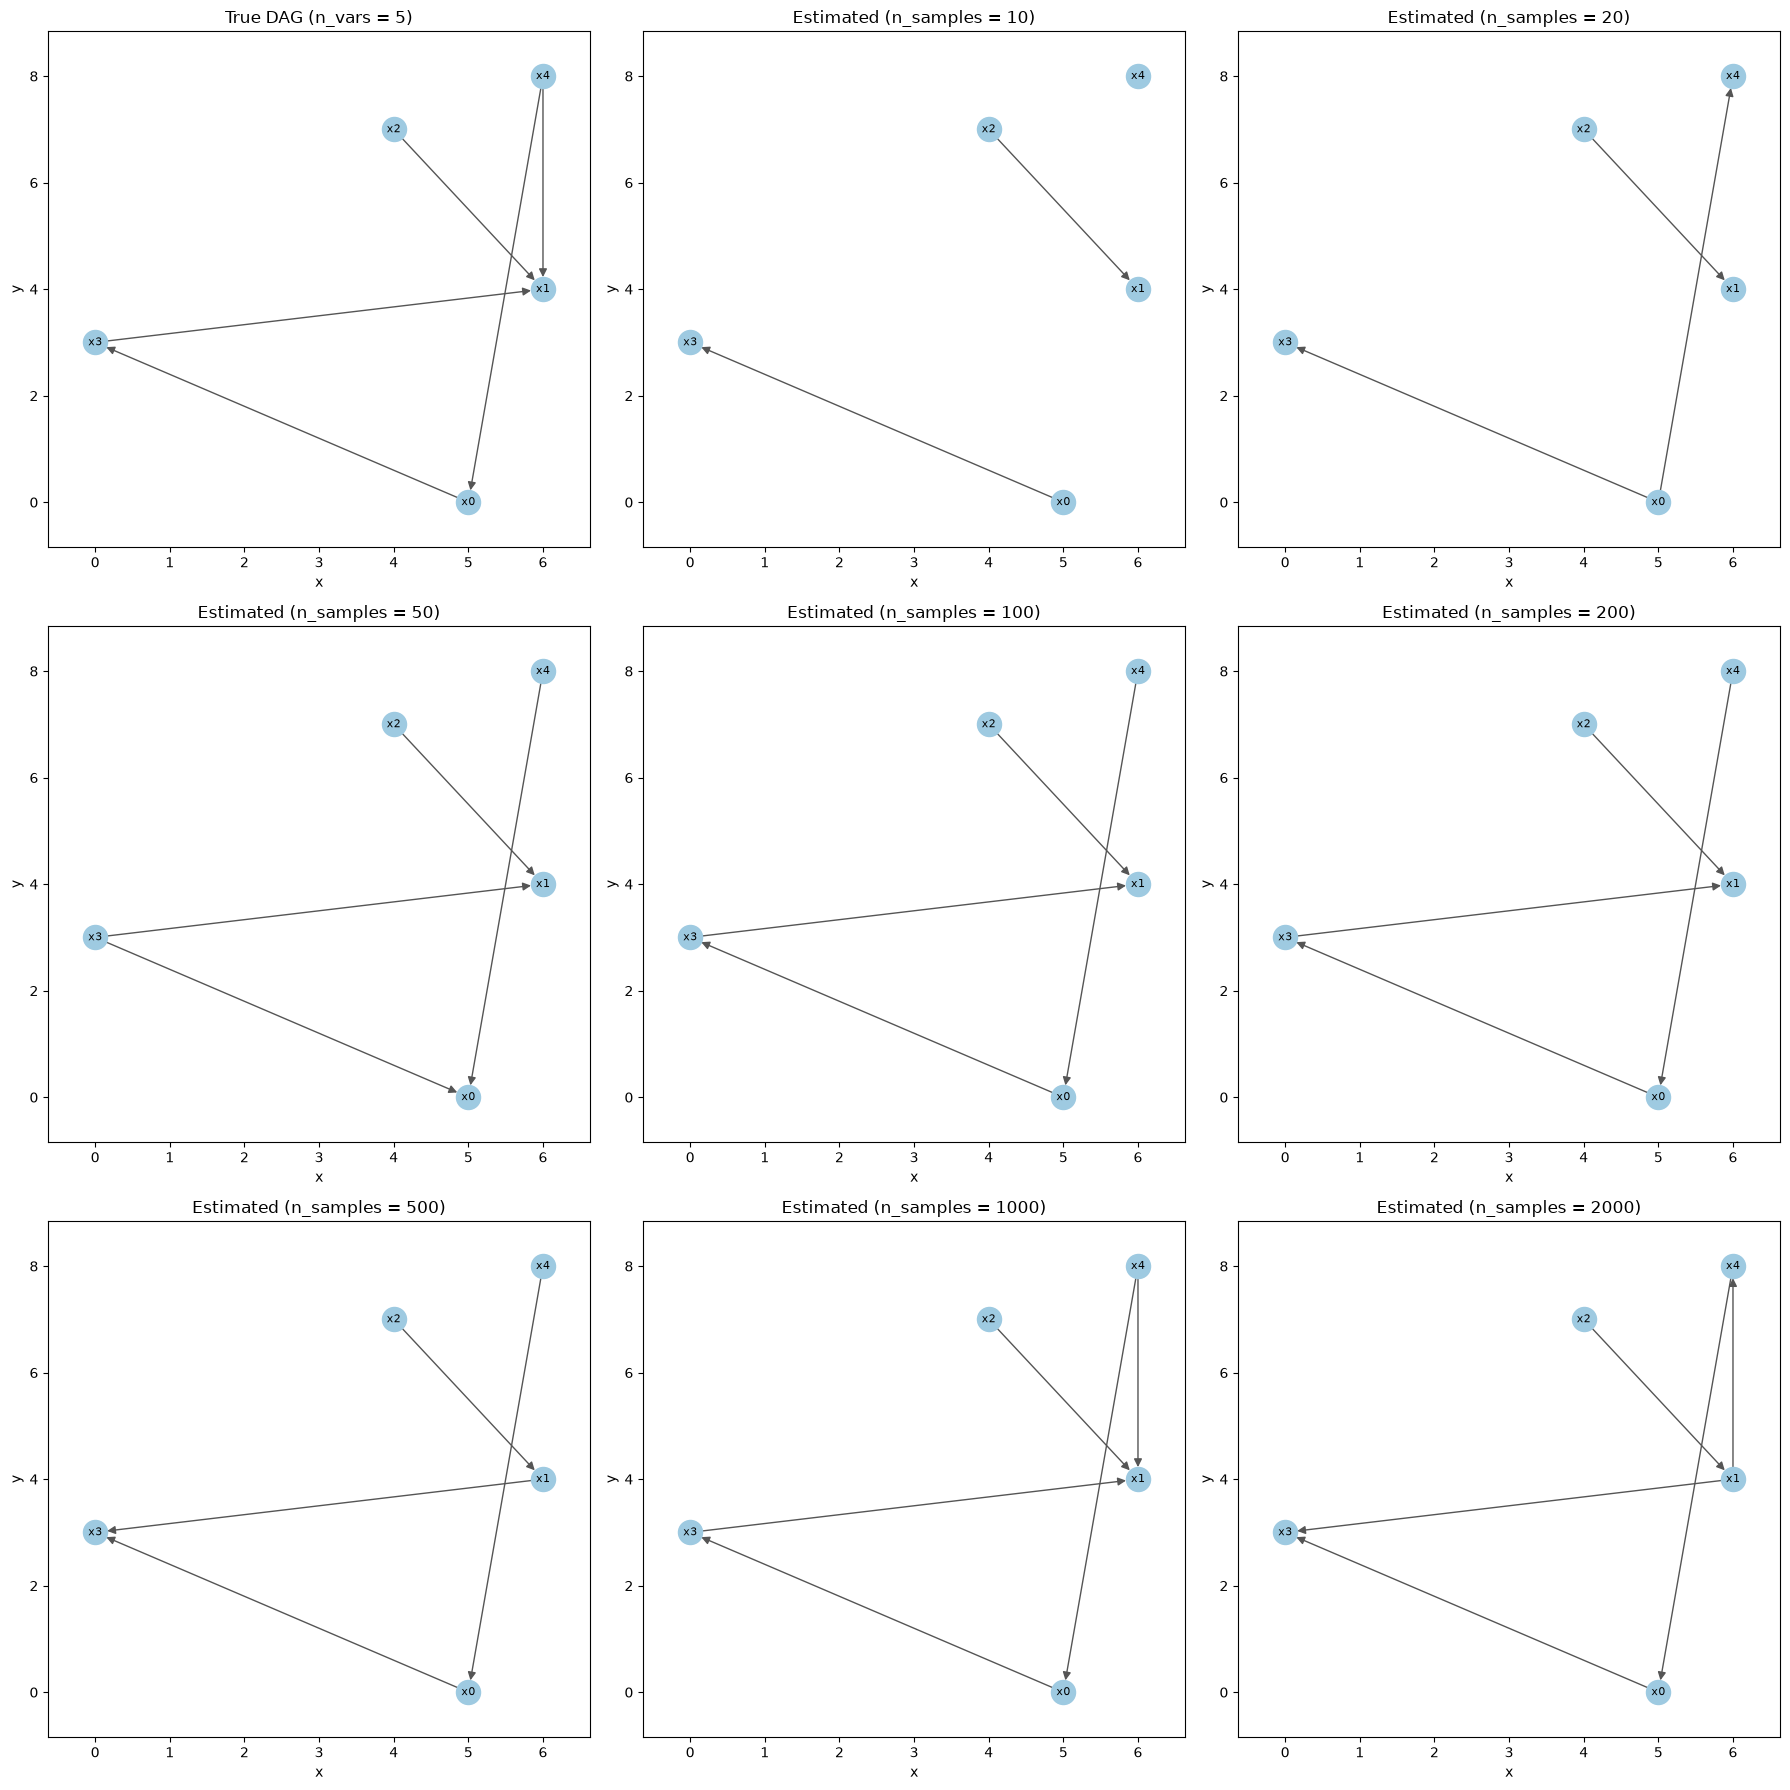

n_vars = 10, n_samples = 10: estimation took 1.57 s, precision = 0.33, recall = 0.10
n_vars = 10, n_samples = 20: estimation took 1.71 s, precision = 1.00, recall = 0.40
n_vars = 10, n_samples = 50: estimation took 1.55 s, precision = 0.86, recall = 0.60
n_vars = 10, n_samples = 100: estimation took 1.54 s, precision = 0.78, recall = 0.70
n_vars = 10, n_samples = 200: estimation took 1.48 s, precision = 0.50, recall = 0.50
n_vars = 10, n_samples = 500: estimation took 1.46 s, precision = 0.73, recall = 0.80
n_vars = 10, n_samples = 1000: estimation took 1.73 s, precision = 0.45, recall = 0.50
n_vars = 10, n_samples = 2000: estimation took 2.00 s, precision = 0.55, recall = 0.60


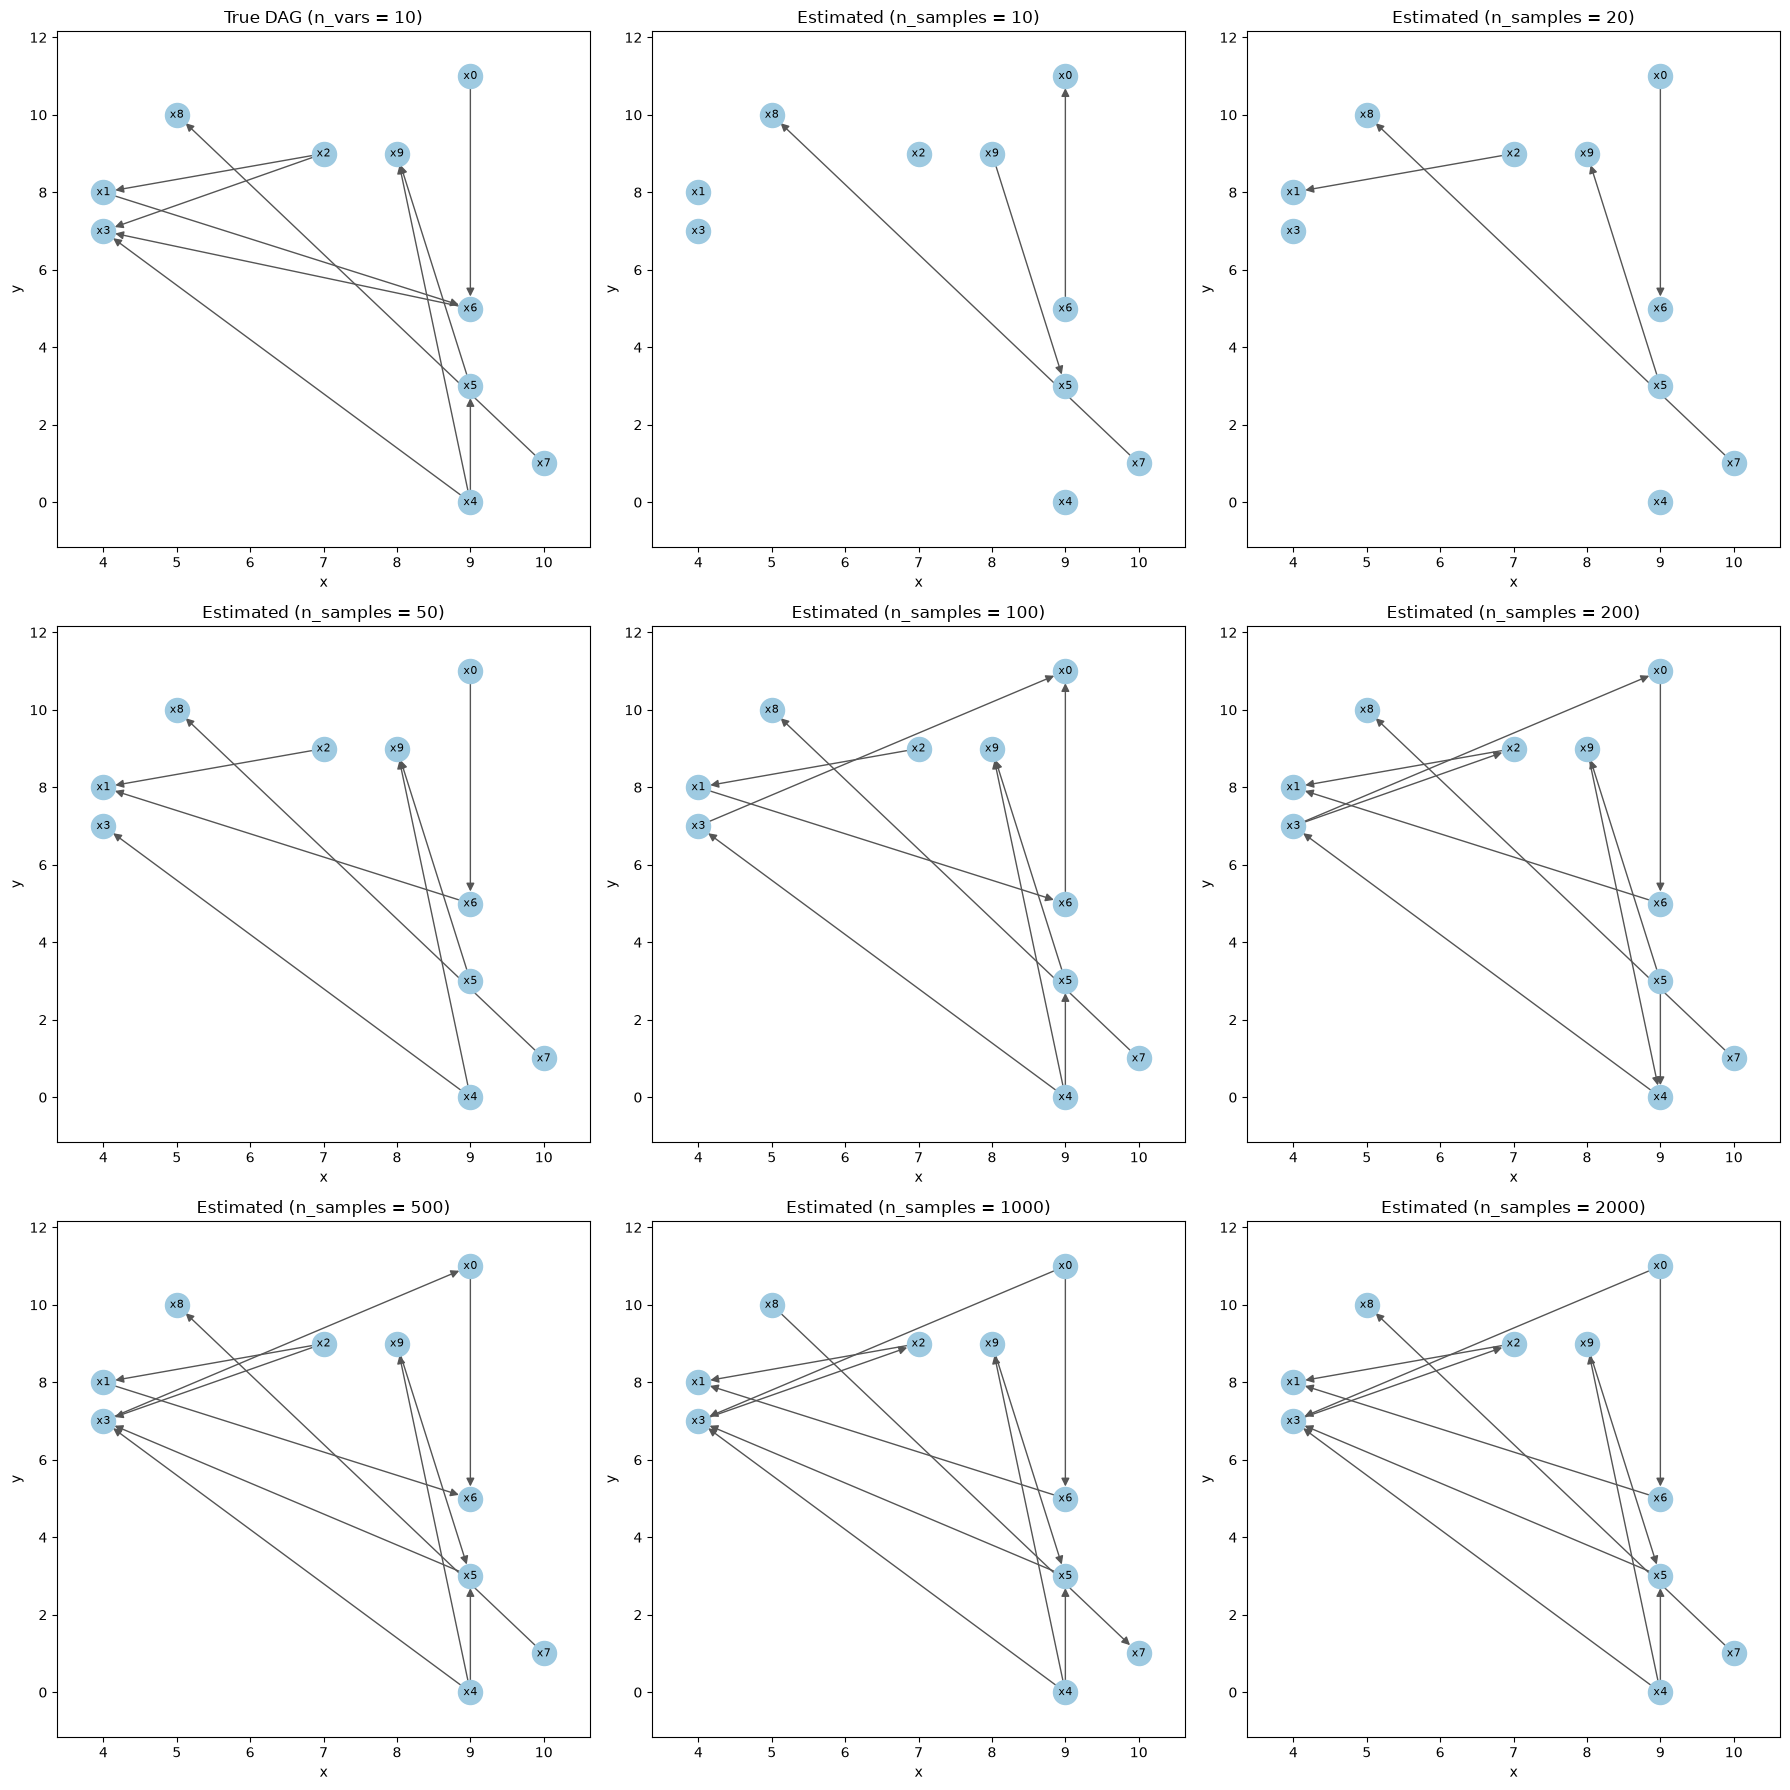

n_vars = 20, n_samples = 10: estimation took 1.27 s, precision = 0.86, recall = 0.33
n_vars = 20, n_samples = 20: estimation took 1.44 s, precision = 0.55, recall = 0.33
n_vars = 20, n_samples = 50: estimation took 1.45 s, precision = 0.75, recall = 0.50
n_vars = 20, n_samples = 100: estimation took 1.45 s, precision = 0.65, recall = 0.61
n_vars = 20, n_samples = 200: estimation took 1.64 s, precision = 0.72, recall = 0.72
n_vars = 20, n_samples = 500: estimation took 1.69 s, precision = 0.83, recall = 0.83
n_vars = 20, n_samples = 1000: estimation took 2.09 s, precision = 0.72, recall = 0.72
n_vars = 20, n_samples = 2000: estimation took 2.17 s, precision = 0.75, recall = 0.83


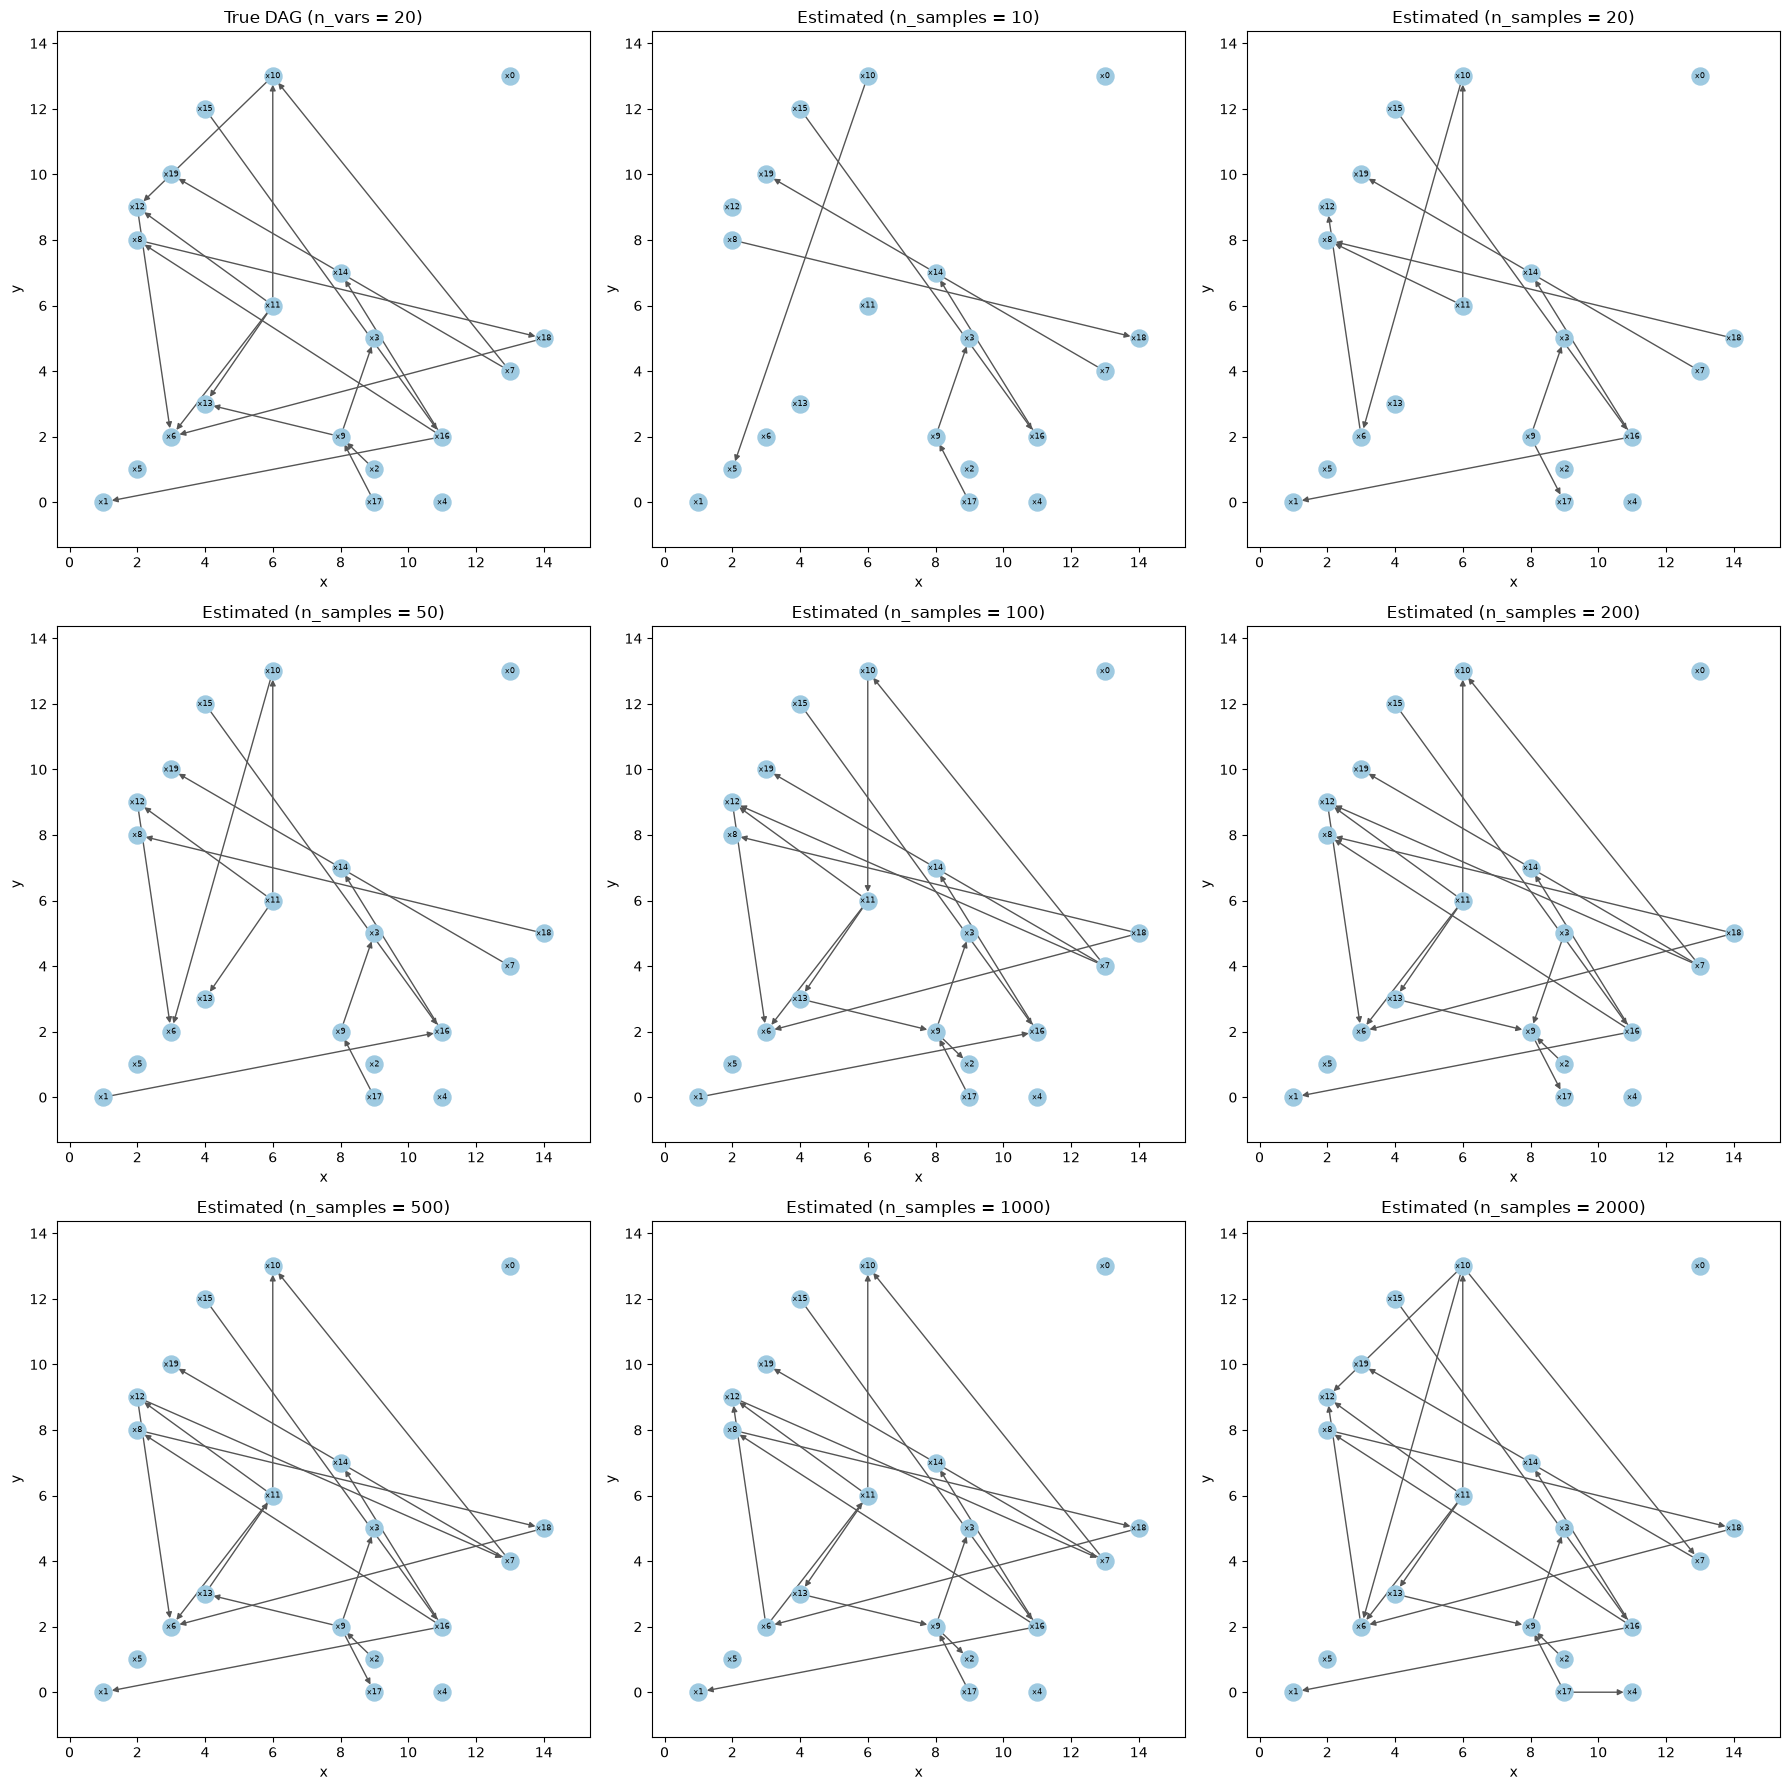

n_vars = 50, n_samples = 10: estimation took 2.25 s, precision = 0.73, recall = 0.15
n_vars = 50, n_samples = 20: estimation took 2.55 s, precision = 0.38, recall = 0.17
n_vars = 50, n_samples = 50: estimation took 2.36 s, precision = 0.61, recall = 0.44
n_vars = 50, n_samples = 100: estimation took 2.46 s, precision = 0.65, recall = 0.54
n_vars = 50, n_samples = 200: estimation took 2.58 s, precision = 0.70, recall = 0.63
n_vars = 50, n_samples = 500: estimation took 3.57 s, precision = 0.76, recall = 0.75
n_vars = 50, n_samples = 1000: estimation took 3.47 s, precision = 0.78, recall = 0.73
n_vars = 50, n_samples = 2000: estimation took 7.01 s, precision = 0.70, recall = 0.71


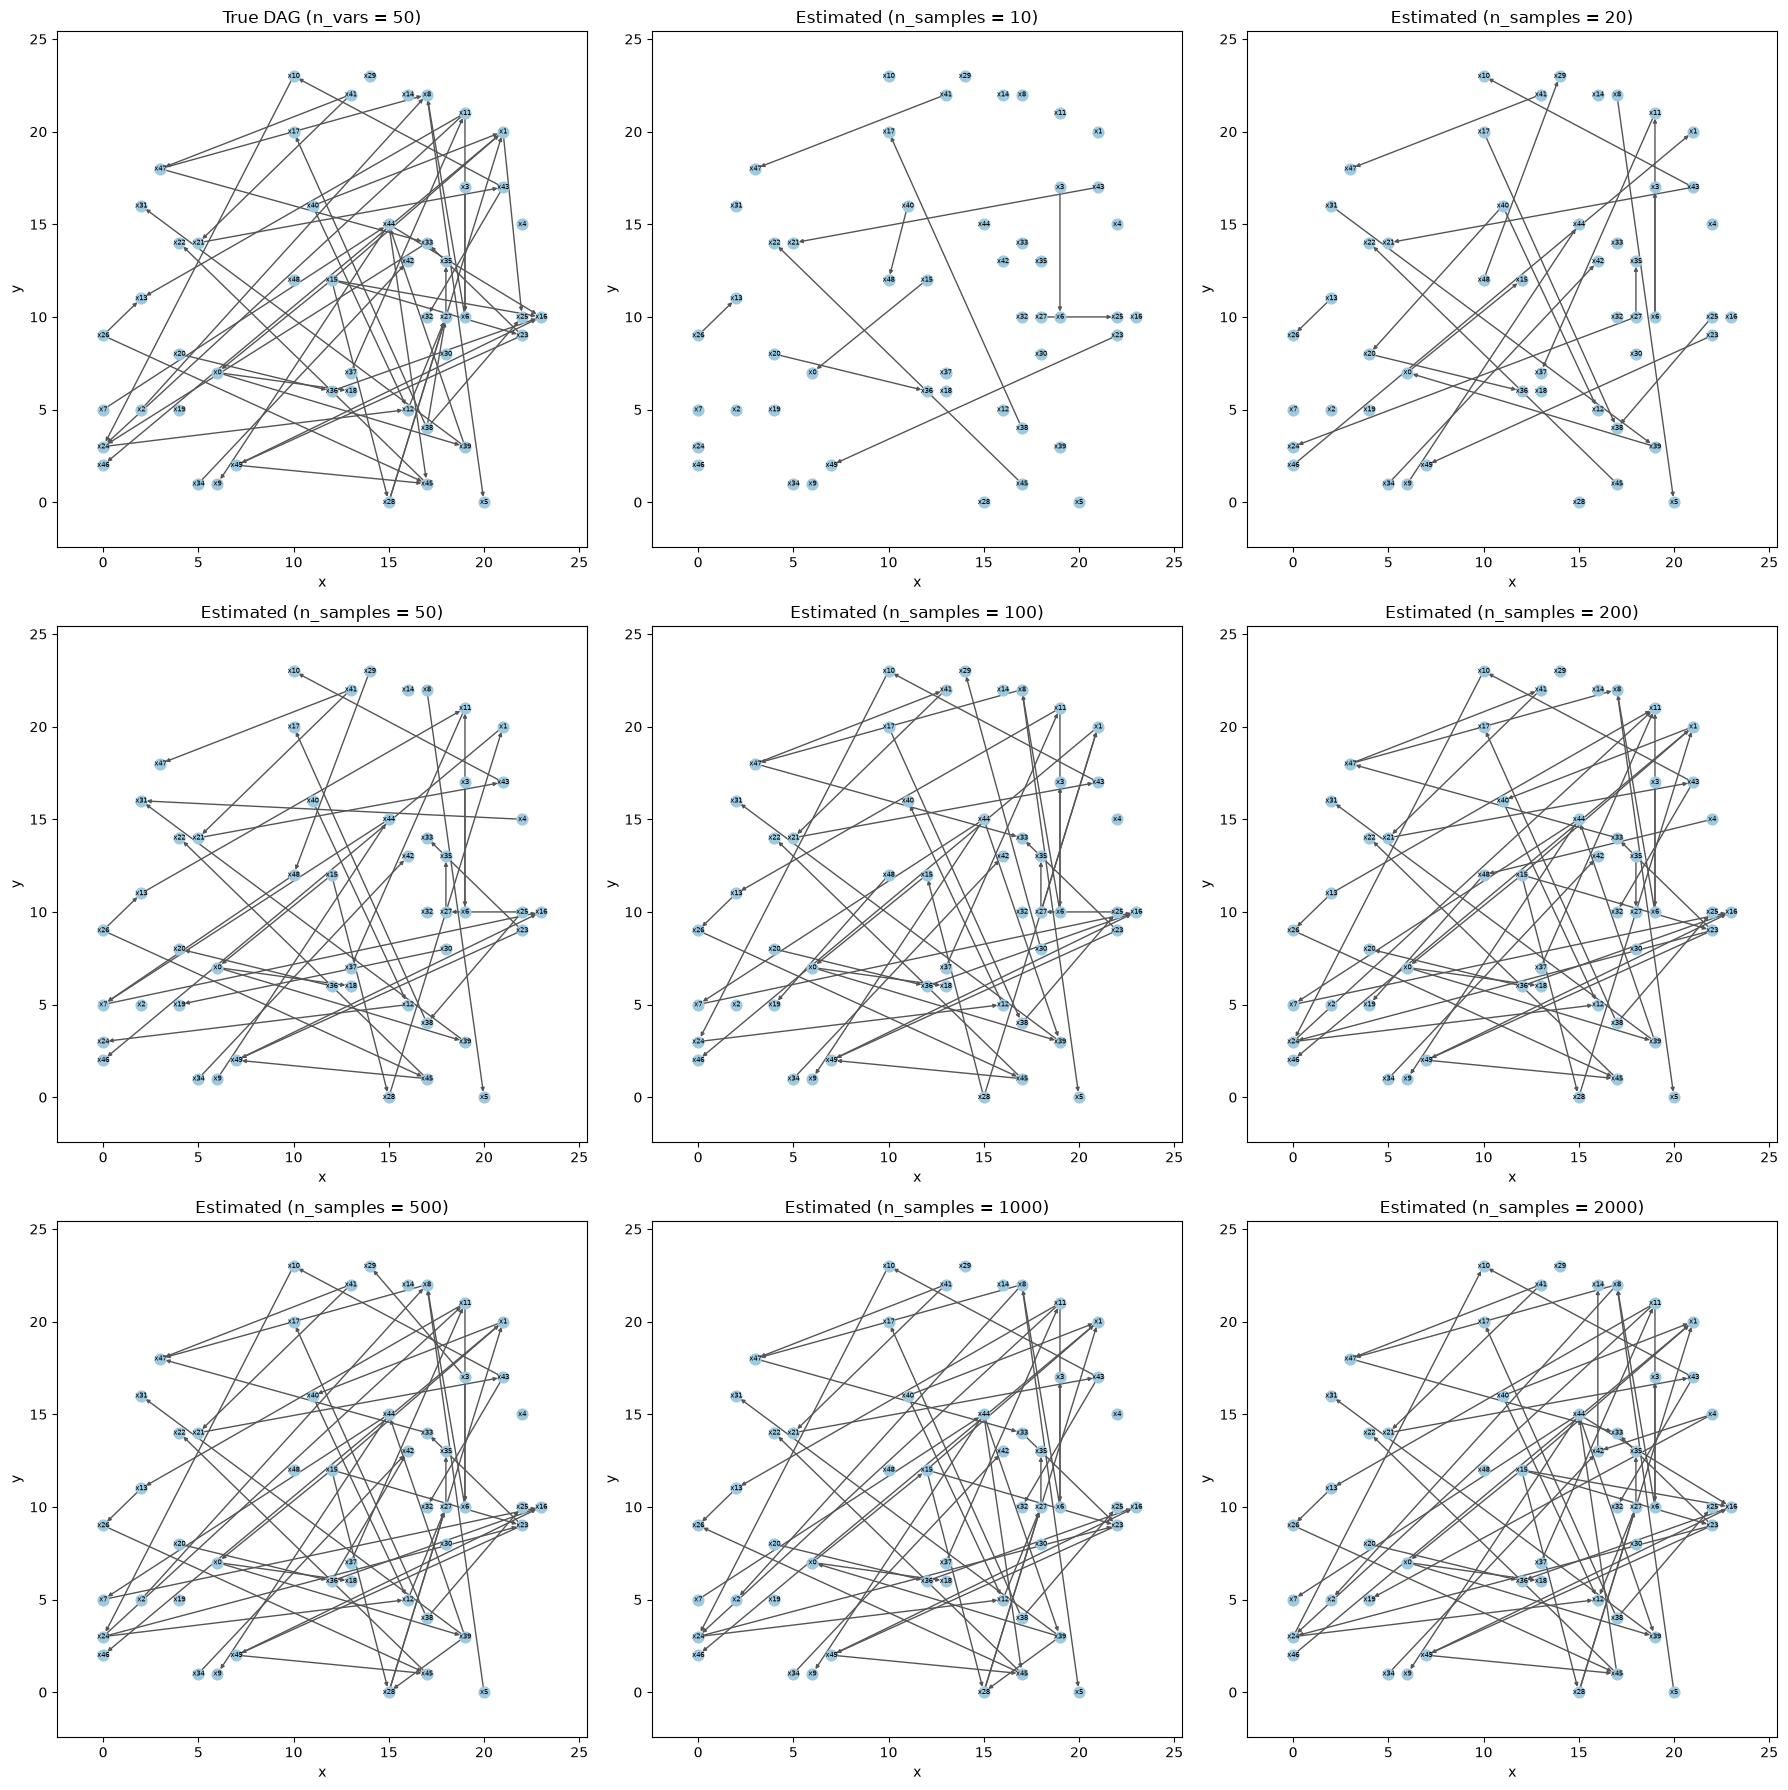

n_vars = 100, n_samples = 10: estimation took 7.36 s, precision = 0.29, recall = 0.06
n_vars = 100, n_samples = 20: estimation took 7.95 s, precision = 0.51, recall = 0.26
n_vars = 100, n_samples = 50: estimation took 7.63 s, precision = 0.68, recall = 0.50
n_vars = 100, n_samples = 100: estimation took 8.86 s, precision = 0.56, recall = 0.54
n_vars = 100, n_samples = 200: estimation took 17.98 s, precision = 0.66, recall = 0.64
n_vars = 100, n_samples = 500: estimation took 22.03 s, precision = 0.60, recall = 0.66
n_vars = 100, n_samples = 1000: estimation took 44.99 s, precision = 0.61, recall = 0.68
n_vars = 100, n_samples = 2000: estimation took 67.27 s, precision = 0.63, recall = 0.69


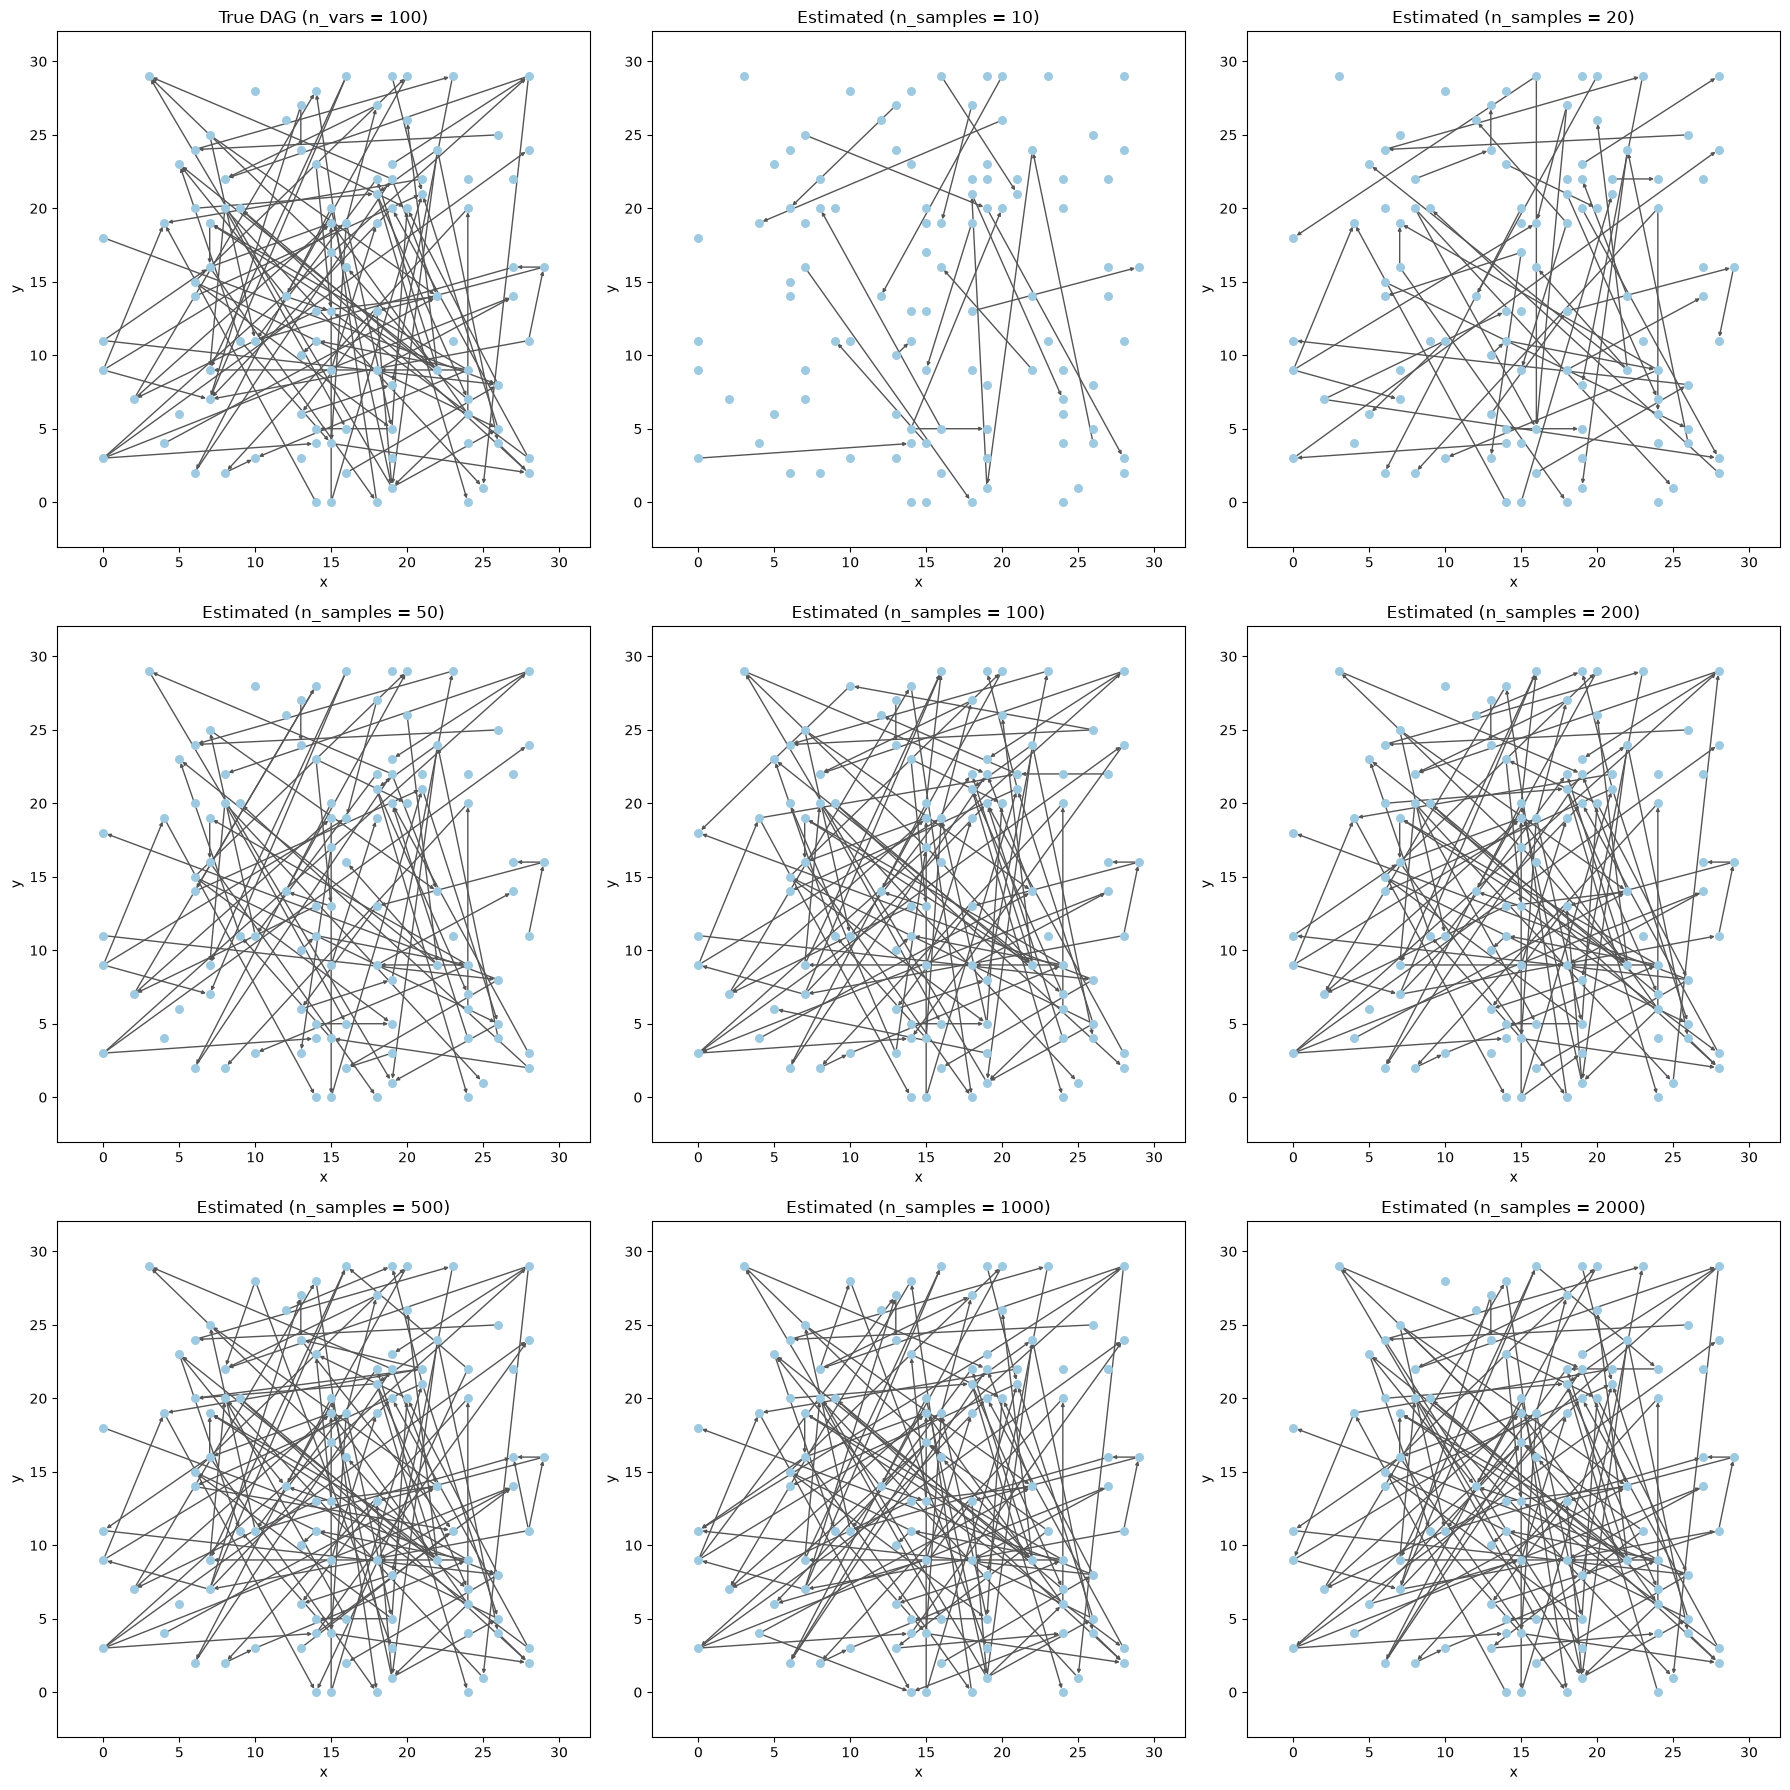

n_vars = 200, n_samples = 10: estimation took 148.13 s, precision = 0.54, recall = 0.12
n_vars = 200, n_samples = 20: estimation took 153.42 s, precision = 0.55, recall = 0.29
n_vars = 200, n_samples = 50: estimation took 157.92 s, precision = 0.57, recall = 0.48
n_vars = 200, n_samples = 100: estimation took 159.26 s, precision = 0.60, recall = 0.57
n_vars = 200, n_samples = 200: estimation took 186.35 s, precision = 0.55, recall = 0.63
n_vars = 200, n_samples = 500: estimation took 210.88 s, precision = 0.55, recall = 0.65
n_vars = 200, n_samples = 1000: estimation took 373.60 s, precision = 0.57, recall = 0.68
n_vars = 200, n_samples = 2000: estimation took 314.89 s, precision = 0.56, recall = 0.69


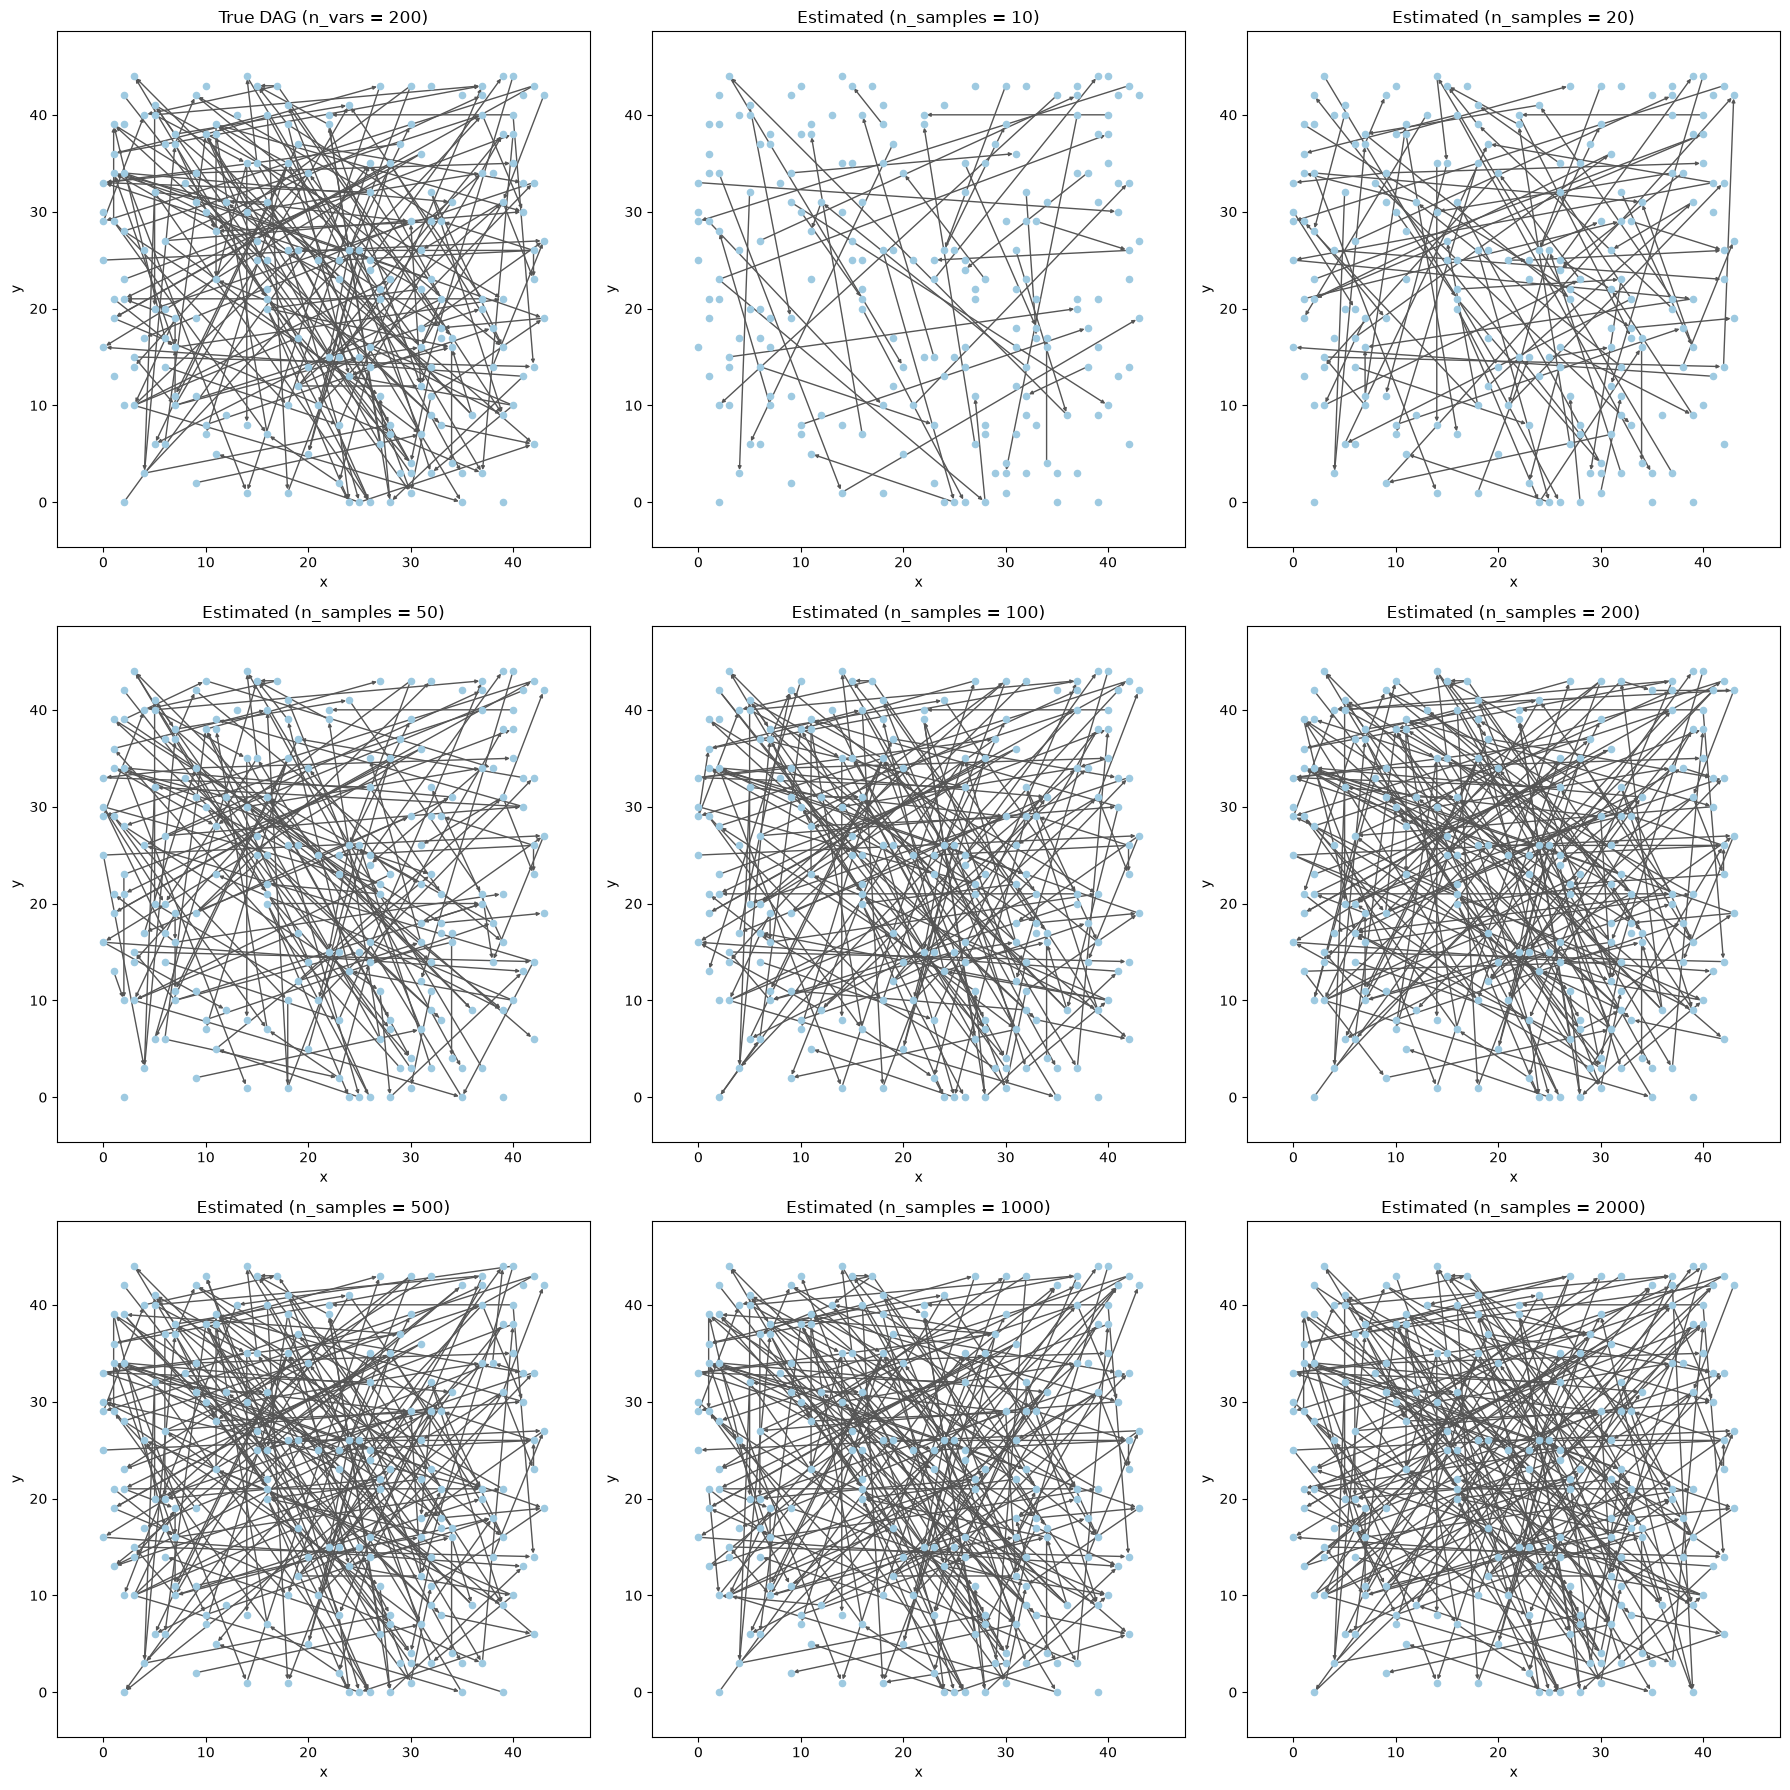

In [3]:
max_samples = max(CONFIG["n_samples"])
for n_vars in CONFIG["n_vars"]:
    # One true DAG (structure, coefficients, coordinates) per number of variables.
    edge_prob = min(1.0, CONFIG["expected_degree"] / max(n_vars - 1, 1))
    sim = simulate(n_vars, max_samples, "random", edge_prob, CONFIG["seed"])

    n_panels = 1 + len(CONFIG["n_samples"])
    n_cols = min(n_panels, CONFIG["panels_per_row"])
    n_rows = -(-n_panels // n_cols)  # ceiling division
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 6 * n_rows), sharex=True, sharey=True, squeeze=False)
    axes = axes.flatten()
    for ax in axes[n_panels:]:
        ax.set_visible(False)
    plot_dag(sim["B_true"], sim["coords"], ax=axes[0], title=f"True DAG (n_vars = {n_vars})")
    for ax, n_samples in zip(axes[1:], CONFIG["n_samples"]):
        start = time.perf_counter()
        B_est, _ = estimate_dag(sim["X"].iloc[:n_samples], CONFIG["pc_alpha"], CONFIG["seed"], CONFIG["lingam_params"])
        elapsed = time.perf_counter() - start
        precision, recall = precision_recall(sim["B_true"], B_est)
        print(
            f"n_vars = {n_vars}, n_samples = {n_samples}: estimation took {elapsed:.2f} s, "
            f"precision = {precision:.2f}, recall = {recall:.2f}"
        )
        plot_dag(B_est, sim["coords"], ax=ax, title=f"Estimated (n_samples = {n_samples})")
    fig.tight_layout()
    plt.show()